[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/07_chembl_data_access.ipynb)

# 07 · Getting Bioactivity Data from ChEMBL

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

[ChEMBL](https://www.ebi.ac.uk/chembl/) (EMBL-EBI) is the largest open database of
bioactivity data from the medicinal-chemistry literature: more than 24 million activity measurements.
This notebook talks to its REST API directly so you understand what happens under the hood.

**Offline-friendly:** if the API cannot be reached (no internet, firewall, ChEMBL maintenance), every
request falls back to a cached copy of the same query stored in `data/chembl_cache/`, so the notebook
always runs. Set the environment variable `COURSE_OFFLINE=1` to force offline mode.

**Learning objectives.** By the end of this notebook you will be able to:

- query the ChEMBL REST API with `requests` (status, target search, activities)
- choose the right target among many search hits
- download paginated activity records robustly (timeouts, retries, offline fallback)
- turn raw records into a one-row-per-compound pIC50 table

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit', 'requests'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
import json, time
import requests

BASE = "https://www.ebi.ac.uk/chembl/api/data"
CACHE = f"{DATA_DIR}/chembl_cache"
OFFLINE = os.environ.get("COURSE_OFFLINE") == "1"

def get_json(endpoint, params=None, retries=3, timeout=20):
    """GET a ChEMBL API endpoint with a timeout and exponential back-off."""
    if OFFLINE:
        raise ConnectionError("offline mode (COURSE_OFFLINE=1)")
    for attempt in range(retries):
        try:
            r = requests.get(f"{BASE}/{endpoint}", params=params, timeout=timeout)
            r.raise_for_status()
            return r.json()
        except requests.RequestException as err:
            if attempt == retries - 1:
                raise ConnectionError(f"ChEMBL API unreachable: {err}") from err
            time.sleep(2 ** attempt)

## 1. Is the API up? Which ChEMBL release?

Always record the ChEMBL release you used: results change between releases.

In [3]:
try:
    status = get_json("status.json")
    SOURCE = "live ChEMBL API"
except ConnectionError as err:
    print("⚠️", err, "→ using the cached copy in data/chembl_cache/")
    with open(f"{CACHE}/metadata.json") as fh:
        status = json.load(fh)
    SOURCE = f"offline cache (retrieved {status['retrieved']})"
print("Data source:", SOURCE)
print("ChEMBL release:", status["chembl_db_version"], "| release date:", status["chembl_release_date"])

Data source: live ChEMBL API
ChEMBL release: ChEMBL_37 | release date: 2026-05-01


## 2. Finding the target

Searching for a protein name returns many targets: orthologues from other species, complexes,
protein families. Picking the wrong one is one of the most common beginner mistakes.

In [4]:
QUERY = "acetylcholinesterase"
try:
    hits = get_json("target/search.json", {"q": QUERY, "limit": 50})["targets"]
    targets = pd.DataFrame([{k: t[k] for k in ["target_chembl_id", "pref_name", "target_type", "organism", "score"]}
                            for t in hits])
except ConnectionError:
    targets = pd.read_csv(f"{CACHE}/target_search_acetylcholinesterase.csv")
print(len(targets), f"targets match '{QUERY}'")
targets.head(10)

31 targets match 'acetylcholinesterase'


,target_chembl_id,pref_name,target_type,organism,score
0,CHEMBL2242744,Acetylcholinesterase,SINGLE PROTEIN,Drosophila melanogaster,18.0
1,CHEMBL220,Acetylcholinesterase,SINGLE PROTEIN,Homo sapiens,16.0
2,CHEMBL4780,Acetylcholinesterase,SINGLE PROTEIN,Torpedo californica,16.0
3,CHEMBL3198,Acetylcholinesterase,SINGLE PROTEIN,Mus musculus,16.0
4,CHEMBL3199,Acetylcholinesterase,SINGLE PROTEIN,Rattus norvegicus,16.0
5,CHEMBL4078,Acetylcholinesterase,SINGLE PROTEIN,Electrophorus electricus,16.0
6,CHEMBL4768,Acetylcholinesterase,SINGLE PROTEIN,Bos taurus,16.0
7,CHEMBL2046266,Acetylcholinesterase,SINGLE PROTEIN,Anopheles gambiae,16.0
8,CHEMBL2366409,AChE2,SINGLE PROTEIN,Bemisia tabaci,16.0
9,CHEMBL2366490,Acetylcholinesterase,SINGLE PROTEIN,Leptinotarsa decemlineata,16.0


In [5]:
human = targets[(targets.organism == "Homo sapiens") & (targets.target_type == "SINGLE PROTEIN")]
human

,target_chembl_id,pref_name,target_type,organism,score
1,CHEMBL220,Acetylcholinesterase,SINGLE PROTEIN,Homo sapiens,16.0
14,CHEMBL6067022,Protein CutA,SINGLE PROTEIN,Homo sapiens,16.0
30,CHEMBL1914,Cholinesterase,SINGLE PROTEIN,Homo sapiens,5.0


In [6]:
TARGET = "CHEMBL220"     # human acetylcholinesterase, a classic Alzheimer's disease target
print(targets.loc[targets.target_chembl_id == TARGET, ["pref_name", "organism"]].to_string(index=False))

           pref_name     organism
Acetylcholinesterase Homo sapiens


## 3. Downloading activities with pagination

The API returns results in **pages** (here 500 records each) with a `page_meta` block telling you
the total count and the URL of the next page. We filter on the server (`standard_type=IC50`,
`assay_type=B` for binding assays) and request only the columns we need (`only=`), which makes
downloads much faster. To keep the lesson quick we stop after 1,000 records; remove `MAX_RECORDS`
to get everything.

In [7]:
FIELDS = ["activity_id", "molecule_chembl_id", "canonical_smiles", "standard_type",
          "standard_relation", "standard_value", "standard_units", "pchembl_value",
          "assay_chembl_id", "assay_type", "data_validity_comment",
          "document_chembl_id", "document_year", "target_chembl_id"]
MAX_RECORDS, PAGE_SIZE = 1000, 500

def fetch_activities(target_id, max_records=MAX_RECORDS):
    rows, offset, total = [], 0, None
    while len(rows) < max_records:
        page = get_json("activity.json", {
            "target_chembl_id": target_id, "standard_type": "IC50", "assay_type": "B",
            "only": ",".join(FIELDS), "limit": PAGE_SIZE, "offset": offset,
            "order_by": "activity_id"})
        total = page["page_meta"]["total_count"]
        rows.extend(page["activities"])
        print(f"  downloaded {len(rows):>5} / {total} records")
        if not page["page_meta"]["next"]:
            break
        offset += PAGE_SIZE
    return pd.DataFrame(rows[:max_records])[FIELDS]

try:
    acts = fetch_activities(TARGET)
    ACT_SOURCE = "live ChEMBL API"
except ConnectionError as err:
    print("⚠️", err, "→ loading cached records")
    acts = pd.read_csv(f"{CACHE}/activities_{TARGET}_IC50.csv")
    ACT_SOURCE = "offline cache"
print(ACT_SOURCE, "|", acts.shape)
acts.head()

  downloaded   500 / 9882 records


  downloaded  1000 / 9882 records
live ChEMBL API | (1000, 14)


,activity_id,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,pchembl_value,assay_chembl_id,assay_type,data_validity_comment,document_chembl_id,document_year,target_chembl_id
0,33969,CHEMBL133897,CCOc1nn(-c2cccc(OCc3ccccc3)c2)c(=O)o1,IC50,=,750.0,nM,6.12,CHEMBL643384,B,NaN,CHEMBL1148382,2004,CHEMBL220
1,37563,CHEMBL336398,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC1CC1,IC50,=,100.0,nM,7.00,CHEMBL643384,B,NaN,CHEMBL1148382,2004,CHEMBL220
2,37565,CHEMBL131588,CN(C(=O)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F)c1ccccc1,IC50,>,50000.0,nM,NaN,CHEMBL643384,B,NaN,CHEMBL1148382,2004,CHEMBL220
3,38902,CHEMBL130628,O=C(N1CCCCC1)n1nc(-c2ccc(Cl)cc2)nc1SCC(F)(F)F,IC50,=,300.0,nM,6.52,CHEMBL643384,B,NaN,CHEMBL1148382,2004,CHEMBL220
4,41170,CHEMBL130478,CSc1nc(-c2ccc(OC(F)(F)F)cc2)nn1C(=O)N(C)C,IC50,=,800.0,nM,6.10,CHEMBL643384,B,NaN,CHEMBL1148382,2004,CHEMBL220


> **Tip:** never paste a SMILES directly into a URL: characters like `#` and `+` break it.
> Pass parameters through `params=` as above and let `requests` encode them.

## 4. What did we get?

In [8]:
acts["standard_value"] = pd.to_numeric(acts["standard_value"], errors="coerce")
acts["pchembl_value"] = pd.to_numeric(acts["pchembl_value"], errors="coerce")
print("unique molecules:", acts["molecule_chembl_id"].nunique())
print("unique assays:   ", acts["assay_chembl_id"].nunique())
print("unique documents:", acts["document_chembl_id"].nunique())
print("\nunits:\n" + acts["standard_units"].value_counts(dropna=False).to_string())
print("\nrelations:\n" + acts["standard_relation"].value_counts(dropna=False).to_string())

unique molecules: 759
unique assays:    86
unique documents: 56

units:
standard_units
nM    1000

relations:
standard_relation
=      888
>       86
NaN     21
<        3
~        2


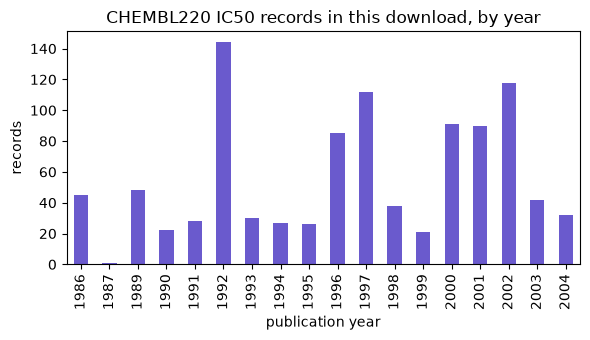

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
acts["document_year"].dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax, color="slateblue")
ax.set_xlabel("publication year"); ax.set_ylabel("records")
ax.set_title(f"{TARGET} IC50 records in this download, by year")
plt.tight_layout(); plt.show()

## 5. From records to an ML-ready table

`pchembl_value` is ChEMBL's standardized −log10 activity, only filled in for exact (`=`) values
in compatible units. Using it is the simplest way to get a clean potency column.

In [10]:
clean = acts[acts["pchembl_value"].notna()
             & acts["canonical_smiles"].notna()
             & acts["data_validity_comment"].isna()]
table = (clean.groupby("molecule_chembl_id")
              .agg(smiles=("canonical_smiles", "first"),
                   pIC50=("pchembl_value", "median"),
                   n=("pchembl_value", "size"))
              .reset_index())
print(f"{len(acts)} records → {len(clean)} usable → {len(table)} compounds")
table.sort_values("pIC50", ascending=False).head()

1000 records → 823 usable → 600 compounds


,molecule_chembl_id,smiles,pIC50,n
348,CHEMBL340427,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,9.52,1
452,CHEMBL543655,CNC(=O)Oc1cccc(CN(C)CCCCCCCOc2ccc3c(=O)c4ccccc...,9.49,1
306,CHEMBL329012,O=C(O)/C=C\C(=O)O.O=C1Cc2cc3c(CCC4CCN(Cc5ccccc...,9.48,1
592,CHEMBL94546,CN1C(=O)Cc2cc3c(CCC4CCN(Cc5ccccc5)CC4)noc3cc21...,9.32,1
307,CHEMBL329231,O=C1CCc2cc3c(CCC4CCN(Cc5ccccc5)CC4)noc3cc2N1,9.24,1


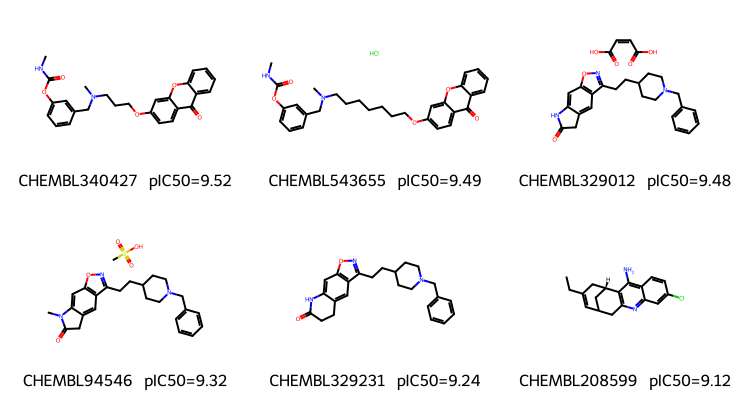

In [11]:
top = table.nlargest(6, "pIC50")
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top["smiles"]], molsPerRow=3, subImgSize=(250, 200),
                     legends=[f"{c}  pIC50={p:.2f}" for c, p in zip(top.molecule_chembl_id, top.pIC50)])

For anything beyond a quick look, apply the structure standardization and replicate checks from Notebook 06.

## 6. Doing all of this in one command with chembl-easy

[**chembl-easy**](https://github.com/hentablihamza/chembl-easy) wraps everything above (retries,
caching, pagination, target resolution from gene symbols or UniProt IDs, unit harmonization, mutant
assay removal, replicate aggregation, and a filtering funnel) into a single command:

```bash
pip install git+https://github.com/hentablihamza/chembl-easy.git
chembl-easy activities EGFR --types IC50 --min-confidence 9 -o egfr_ic50.csv
```

The EGFR dataset used in Notebooks 03–05 and 08–12 (`data/egfr_chembl37_ic50.csv`) was produced exactly this way.
The cell is not executed here so the notebook stays fast and offline-friendly.

### ✏️ Exercise 1

How many of the downloaded records are **not** exact measurements (relation other than `=`)? Why can't we use them directly as regression targets?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
inexact = acts[acts["standard_relation"] != "="]
print(len(inexact), "inexact records")
print(inexact["standard_relation"].value_counts(dropna=False))
# '>' 10000 nM only says 'weaker than 10 µM'. The true value is unknown (censored data).
```

</details>

### ✏️ Exercise 2

Using `targets`, list all **non-human** single-protein acetylcholinesterase targets and count them by organism.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
nonhuman = targets[(targets.organism != "Homo sapiens") & (targets.target_type == "SINGLE PROTEIN")]
print(len(nonhuman), "non-human single-protein targets")
nonhuman["organism"].value_counts().head(10)
```

</details>

### ✏️ Exercise 3

Compute pIC50 yourself from `standard_value` (nM) for the exact, nM records and check that it agrees with `pchembl_value`.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
exact = acts[(acts.standard_relation == "=") & (acts.standard_units == "nM") & (acts.standard_value > 0)].copy()
exact["pIC50_manual"] = 9 - np.log10(exact["standard_value"])
cmp = exact.dropna(subset=["pchembl_value"])
print("records compared:", len(cmp))
print("max absolute difference:", (cmp["pIC50_manual"] - cmp["pchembl_value"]).abs().max().round(3))
```

</details>

## Key takeaways

- Record the ChEMBL release; select targets by organism **and** target type.
- Paginate, filter on the server, request only the fields you need, and handle network failures.
- Prefer exact measurements; inequality-qualified values are censored.

**Data licence note:** ChEMBL data are provided by EMBL-EBI under CC BY-SA 3.0. Cite
Zdrazil *et al.*, *Nucleic Acids Res.* 2024, 52, D1180–D1192 (doi:10.1093/nar/gkad1004) when you use them.

**Next:** [08 · Chemical space visualization](08_chemical_space_visualization.ipynb).